In [1]:
from pathlib import Path
from collections import Counter, defaultdict

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import textdistance

from nltk.tokenize import RegexpTokenizer
from nltk.corpus import stopwords
from spellchecker import SpellChecker
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Download the NLTK stopword list.
nltk.download("stopwords", quiet=True)

DATA_DIR = Path("data/books")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
book_files = list(DATA_DIR.glob("*.txt"))

if not book_files:
    raise FileNotFoundError(
        "No .txt files found. Add Project Gutenberg books "
        "to the data/books/ folder."
    )

texts = []

for file_path in book_files:
    text = file_path.read_text(encoding="utf-8", errors="ignore")
    texts.append(text)

raw_text = "\n".join(texts)

print("Number of books:", len(book_files))
print("Total characters:", len(raw_text))
print("Sample text:\n")
print(raw_text[:1000])

Number of books: 2
Total characters: 794721
Sample text:

The Project Gutenberg eBook of The haters


This eBook is for the use of anyone anywhere in the United States and most other parts of the world at no cost and with almost no restrictions whatsoever. You may copy it, give it away or re-use it under the terms of the Project Gutenberg License included with this eBook or online at www.gutenberg.org. If you are not located in the United States, you will have to check the laws of the country where you are located before using this eBook.

Title: The haters

Author: William Douglas Morrison

Illustrator: Ed Emshwiller





Release date: November 12, 2026 [eBook #79982]

Language: English

Original publication: New York: Space Publications, Inc., 1953

Other information and formats: www.gutenberg.org/ebooks/79982

Credits: Tom Trussel - Stories of Futures Past (This file was produced from images generously made available by The Luminist Archive)




*** START OF THE PROJECT GUTENBERG EB

In [3]:
tokenizer = RegexpTokenizer(r"[a-z]+")

tokens = tokenizer.tokenize(raw_text.lower())

print("Total tokens:", len(tokens))
print("Unique words:", len(set(tokens)))
print("First 30 tokens:", tokens[:30])

Total tokens: 141712
Unique words: 7521
First 30 tokens: ['the', 'project', 'gutenberg', 'ebook', 'of', 'the', 'haters', 'this', 'ebook', 'is', 'for', 'the', 'use', 'of', 'anyone', 'anywhere', 'in', 'the', 'united', 'states', 'and', 'most', 'other', 'parts', 'of', 'the', 'world', 'at', 'no', 'cost']


In [4]:
english_stopwords = set(stopwords.words("english"))

content_tokens = [
    word for word in tokens
    if word not in english_stopwords
]

print("Tokens before stopword filtering:", len(tokens))
print("Tokens after stopword filtering:", len(content_tokens))

Tokens before stopword filtering: 141712
Tokens after stopword filtering: 64647


In [5]:
split_index = int(len(tokens) * 0.80)

train_tokens = tokens[:split_index]
test_tokens = tokens[split_index:]

print("Training tokens:", len(train_tokens))
print("Testing tokens:", len(test_tokens))

Training tokens: 113369
Testing tokens: 28343


In [6]:
from nltk.util import ngrams
from nltk.probability import FreqDist

# Bigram counts: (previous word, next word)
bigram_counts = Counter(ngrams(train_tokens, 2))

# Trigram counts: (previous two words, next word)
trigram_counts = Counter(ngrams(train_tokens, 3))

# NLTK frequency distribution for unigram analysis.
word_freq = FreqDist(train_tokens)

# Candidate continuations indexed by their context.
bigram_next = defaultdict(Counter)
trigram_next = defaultdict(Counter)

for (previous, next_word), count in bigram_counts.items():
    bigram_next[previous][next_word] = count

for (word1, word2, next_word), count in trigram_counts.items():
    trigram_next[(word1, word2)][next_word] = count

print("Unique bigrams:", len(bigram_counts))
print("Unique trigrams:", len(trigram_counts))
print("Unique vocabulary words:", len(word_freq))

Unique bigrams: 53931
Unique trigrams: 96767
Unique vocabulary words: 7125


In [7]:
def predict_bigram(prefix, top_k=3):
    words = tokenizer.tokenize(prefix.lower())

    if not words:
        return []

    context = words[-1]
    candidates = bigram_next.get(context, Counter())

    return [
        word for word, count in candidates.most_common(top_k)
    ]


def predict_trigram(prefix, top_k=3):
    words = tokenizer.tokenize(prefix.lower())

    if not words:
        return []

    # Use the last two words when available.
    if len(words) >= 2:
        context = (words[-2], words[-1])
        candidates = trigram_next.get(context, Counter())

        if candidates:
            return [
                word for word, count in candidates.most_common(top_k)
            ]

    # Back off to a bigram if the trigram context is unseen.
    return predict_bigram(prefix, top_k=top_k)


print("Bigram:", predict_bigram("in the"))
print("Trigram:", predict_trigram("in the"))

Bigram: ['whole', 'same', 'other']
Trigram: ['world', 'room', 'united']


In [8]:
test_prefixes = [
    "in the",
    "of the",
    "to the",
    "it was",
    "there is",
    "he said",
    "she was",
    "one of",
    "i am",
    "as the"
]

prediction_rows = []

for prefix in test_prefixes:
    bigram_predictions = predict_bigram(prefix, top_k=3)
    trigram_predictions = predict_trigram(prefix, top_k=3)

    prediction_rows.append({
        "Input Prefix": prefix,
        "Bigram Top 3": ", ".join(bigram_predictions) or "No prediction",
        "Trigram Top 3": ", ".join(trigram_predictions) or "No prediction"
    })

prediction_df = pd.DataFrame(prediction_rows)
display(prediction_df)

prediction_df.to_csv(
    OUTPUT_DIR / "autocomplete_prefix_tests.csv",
    index=False
)

,Input Prefix,Bigram Top 3,Trigram Top 3
0,in the,"whole, same, other","world, room, united"
1,of the,"whole, same, other","world, family, project"
2,to the,"whole, same, other","project, rest, ship"
3,it was,"not, a, the","not, a, impossible"
4,there is,"not, a, very","no, a, not"
5,he said,"she, elizabeth, he","to, somebody, harshly"
6,she was,"not, a, the","not, very, a"
7,one of,"the, her, his","the, them, her"
8,i am,"sure, not, afraid","sure, not, afraid"
9,as the,"whole, same, other","most, time, first"


In [9]:
def evaluate_autocomplete(test_tokens, top_k=3, max_examples=5000):
    results = []

    # Start at index 2 so both one-word and two-word contexts are possible.
    end_index = min(len(test_tokens), max_examples + 2)

    for i in range(2, end_index):
        actual = test_tokens[i]
        prefix_one = test_tokens[i - 1]
        prefix_two = test_tokens[i - 2] + " " + test_tokens[i - 1]

        bigram_predictions = predict_bigram(prefix_one, top_k)
        trigram_predictions = predict_trigram(prefix_two, top_k)

        results.append({
            "actual": actual,
            "bigram": bigram_predictions,
            "trigram": trigram_predictions
        })

    rows = []

    for model_name in ["bigram", "trigram"]:
        usable = [
            row for row in results
            if row[model_name]
        ]

        if not usable:
            rows.append({
                "Model": model_name.title(),
                "Evaluated Contexts": 0,
                "Top-1 Accuracy": np.nan,
                "Precision@3": np.nan,
                "Recall@3": np.nan
            })
            continue

        hits_top1 = sum(
            row[model_name][0] == row["actual"]
            for row in usable
        )

        hits_top3 = sum(
            row["actual"] in row[model_name][:top_k]
            for row in usable
        )

        total_suggestions = sum(
            len(row[model_name][:top_k])
            for row in usable
        )

        rows.append({
            "Model": model_name.title(),
            "Evaluated Contexts": len(usable),
            "Top-1 Accuracy": hits_top1 / len(usable),
            "Precision@3": (
                hits_top3 / total_suggestions
                if total_suggestions else 0
            ),
            "Recall@3": hits_top3 / len(usable)
        })

    return pd.DataFrame(rows)


autocomplete_metrics = evaluate_autocomplete(test_tokens)
display(autocomplete_metrics.round(4))

autocomplete_metrics.to_csv(
    OUTPUT_DIR / "autocomplete_metrics.csv",
    index=False
)

,Model,Evaluated Contexts,Top-1 Accuracy,Precision@3,Recall@3
0,Bigram,4906,0.1331,0.0809,0.2377
1,Trigram,4906,0.1317,0.0805,0.2112


In [10]:
def levenshtein_distance(word1, word2):
    """Calculate Levenshtein distance using dynamic programming."""
    if len(word1) < len(word2):
        word1, word2 = word2, word1

    previous_row = list(range(len(word2) + 1))

    for i, char1 in enumerate(word1, start=1):
        current_row = [i]

        for j, char2 in enumerate(word2, start=1):
            insert_cost = current_row[j - 1] + 1
            delete_cost = previous_row[j] + 1
            replace_cost = previous_row[j - 1] + (char1 != char2)

            current_row.append(
                min(insert_cost, delete_cost, replace_cost)
            )

        previous_row = current_row

    return previous_row[-1]


def custom_autocorrect(word, max_distance=2):
    word = word.lower().strip()

    # Do not alter a word already in the corpus vocabulary.
    if word in corpus_vocabulary:
        return word

    # Length filtering avoids unnecessary comparisons.
    candidates = [
        candidate for candidate in corpus_vocabulary
        if abs(len(candidate) - len(word)) <= max_distance
    ]

    best_word = word
    best_distance = max_distance + 1
    best_frequency = -1

    for candidate in candidates:
        distance = levenshtein_distance(word, candidate)

        if distance > max_distance:
            continue

        frequency = corpus_frequency[candidate]

        if (
            distance < best_distance
            or (
                distance == best_distance
                and frequency > best_frequency
            )
        ):
            best_word = candidate
            best_distance = distance
            best_frequency = frequency

    return best_word

In [14]:
typo_pairs = [
    ("langauge", "language"),
    ("recieve", "receive"),
    ("definately", "definitely"),
    ("seperate", "separate"),
    ("occured", "occurred"),
    ("untill", "until"),
    ("goverment", "government"),
    ("enviroment", "environment"),
    ("experiance", "experience"),
    ("knowlege", "knowledge"),
    ("acheive", "achieve"),
    ("begining", "beginning"),
    ("beleive", "believe"),
    ("adress", "address"),
    ("freind", "friend"),
    ("wierd", "weird"),
    ("thier", "their"),
    ("wich", "which"),
    ("tommorow", "tomorrow"),
    ("studing", "studying")
]

correction_rows = []

for typo, expected in typo_pairs:
    dictionary_result = spell.correction(typo)
    corpus_result = custom_autocorrect(typo)

    correction_rows.append({
        "Misspelled Word": typo,
        "Expected Word": expected,
        "PySpellChecker": dictionary_result,
        "Custom Levenshtein": corpus_result,
        "PySpellChecker Correct": dictionary_result == expected,
        "Custom Correct": corpus_result == expected
    })

correction_df = pd.DataFrame(correction_rows)
display(correction_df)

correction_df.to_csv(
    OUTPUT_DIR / "autocorrect_test_results.csv",
    index=False
)

,Misspelled Word,Expected Word,PySpellChecker,Custom Levenshtein,PySpellChecker Correct,Custom Correct
0,langauge,language,language,language,True,True
1,recieve,receive,receive,relieve,True,False
2,definately,definitely,definitely,definitely,True,True
3,seperate,separate,separate,separate,True,True
4,occured,occurred,occurred,occurred,True,True
5,untill,until,until,until,True,True
6,goverment,government,government,government,True,True
7,enviroment,environment,environment,enviroment,True,False
8,experiance,experience,experience,experience,True,True
9,knowlege,knowledge,knowledge,knowledge,True,True


In [12]:
from spellchecker import SpellChecker
from collections import Counter

# Initialize the spelling checker
spell = SpellChecker(distance=2)

# Create corpus frequency and vocabulary if not already defined
corpus_frequency = Counter(train_tokens)
corpus_vocabulary = set(corpus_frequency)

print("SpellChecker initialized successfully!")
print("Corpus vocabulary size:", len(corpus_vocabulary))

SpellChecker initialized successfully!
Corpus vocabulary size: 7125


In [13]:
correction_rows = []

for typo, expected in typo_pairs:
    dictionary_result = spell.correction(typo)
    corpus_result = custom_autocorrect(typo)

    correction_rows.append({
        "Misspelled Word": typo,
        "Expected Word": expected,
        "PySpellChecker": dictionary_result,
        "Custom Levenshtein": corpus_result,
        "PySpellChecker Correct": dictionary_result == expected,
        "Custom Correct": corpus_result == expected
    })

correction_df = pd.DataFrame(correction_rows)
display(correction_df)

,Misspelled Word,Expected Word,PySpellChecker,Custom Levenshtein,PySpellChecker Correct,Custom Correct
0,langauge,language,language,language,True,True
1,recieve,receive,receive,relieve,True,False
2,definately,definitely,definitely,definitely,True,True
3,seperate,separate,separate,separate,True,True
4,occured,occurred,occurred,occurred,True,True
5,untill,until,until,until,True,True
6,goverment,government,government,government,True,True
7,enviroment,environment,environment,enviroment,True,False
8,experiance,experience,experience,experience,True,True
9,knowlege,knowledge,knowledge,knowledge,True,True


In [15]:
def correction_metrics(results, prediction_column):
    original = results["Misspelled Word"].tolist()
    expected = results["Expected Word"].tolist()
    predictions = results[prediction_column].fillna("").tolist()

    changed = [
        prediction != word
        for word, prediction in zip(original, predictions)
    ]

    exact = [
        prediction == target
        for prediction, target in zip(predictions, expected)
    ]

    correct_changes = sum(
        did_change and is_exact
        for did_change, is_exact in zip(changed, exact)
    )

    total_changes = sum(changed)
    total_typos = len(original)

    precision = (
        correct_changes / total_changes
        if total_changes else 0.0
    )
    recall = correct_changes / total_typos if total_typos else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "Algorithm": prediction_column,
        "Test Words": total_typos,
        "Exact Correction Accuracy": np.mean(exact),
        "Correction Precision": precision,
        "Correction Recall": recall,
        "Correction F1": f1
    }


spell_metrics = pd.DataFrame([
    correction_metrics(correction_df, "PySpellChecker"),
    correction_metrics(correction_df, "Custom Levenshtein")
])

display(spell_metrics.round(4))

spell_metrics.to_csv(
    OUTPUT_DIR / "autocorrect_metrics.csv",
    index=False
)

,Algorithm,Test Words,Exact Correction Accuracy,Correction Precision,Correction Recall,Correction F1
0,PySpellChecker,20,0.90,0.9000,0.90,0.9000
1,Custom Levenshtein,20,0.65,0.7222,0.65,0.6842


In [16]:
control_words = [
    "language",
    "receive",
    "definitely",
    "separate",
    "government",
    "environment",
    "experience",
    "knowledge",
    "achieve",
    "beginning"
]

control_rows = []

for word in control_words:
    control_rows.append({
        "Input Word": word,
        "Expected Word": word,
        "Needs Correction": 0,
        "PySpellChecker": spell.correction(word),
        "Custom Levenshtein": custom_autocorrect(word)
    })

for typo, expected in typo_pairs:
    control_rows.append({
        "Input Word": typo,
        "Expected Word": expected,
        "Needs Correction": 1,
        "PySpellChecker": spell.correction(typo),
        "Custom Levenshtein": custom_autocorrect(typo)
    })

detection_df = pd.DataFrame(control_rows)

for column in ["PySpellChecker", "Custom Levenshtein"]:
    detection_df[column + " Flags Change"] = (
        detection_df[column].fillna("")
        != detection_df["Input Word"]
    ).astype(int)

display(detection_df.head(12))

,Input Word,Expected Word,Needs Correction,PySpellChecker,Custom Levenshtein,PySpellChecker Flags Change,Custom Levenshtein Flags Change
0,language,language,0,language,language,0,0
1,receive,receive,0,receive,receive,0,0
2,definitely,definitely,0,definitely,definitely,0,0
3,separate,separate,0,separate,separate,0,0
4,government,government,0,government,government,0,0
5,environment,environment,0,environment,environment,0,0
6,experience,experience,0,experience,experience,0,0
7,knowledge,knowledge,0,knowledge,knowledge,0,0
8,achieve,achieve,0,achieve,achieve,0,0
9,beginning,beginning,0,beginning,beginning,0,0


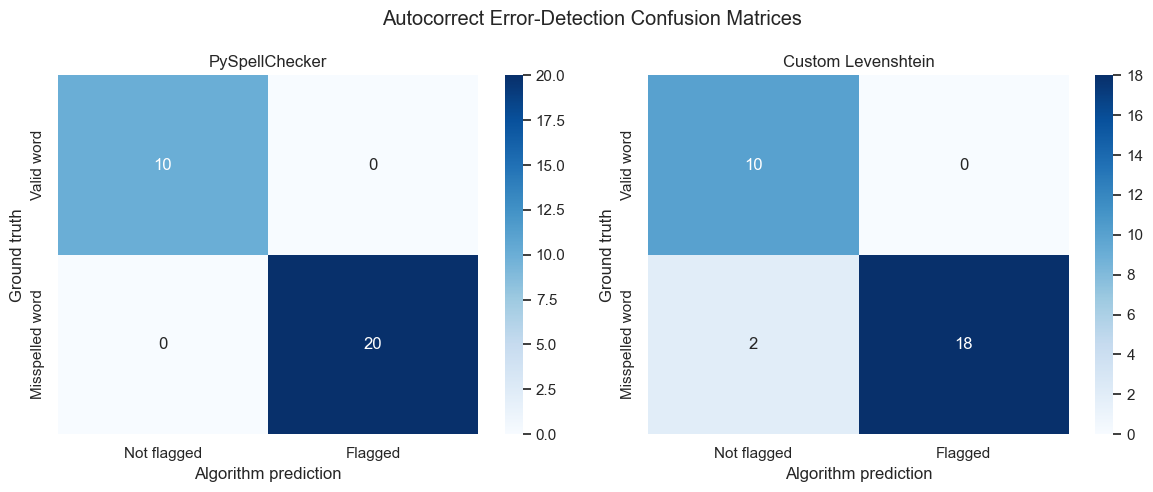

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, column, title in [
    (axes[0], "PySpellChecker Flags Change", "PySpellChecker"),
    (axes[1], "Custom Levenshtein Flags Change", "Custom Levenshtein")
]:
    cm = confusion_matrix(
        detection_df["Needs Correction"],
        detection_df[column],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not flagged", "Flagged"],
        yticklabels=["Valid word", "Misspelled word"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Algorithm prediction")
    ax.set_ylabel("Ground truth")

plt.suptitle("Autocorrect Error-Detection Confusion Matrices")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "autocorrect_confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

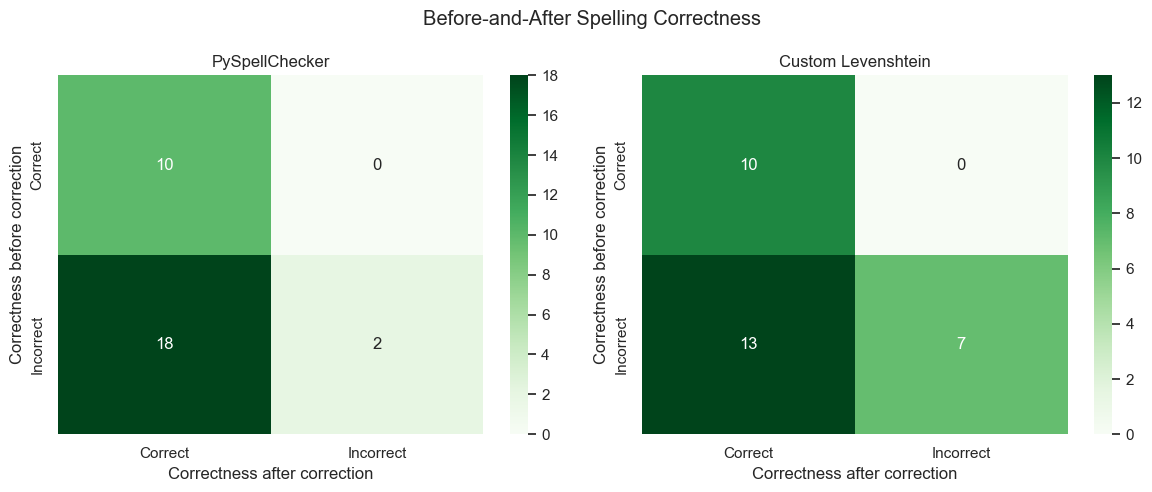

In [18]:
transition_rows = []

for _, row in detection_df.iterrows():
    before_correct = row["Input Word"] == row["Expected Word"]

    for algorithm in ["PySpellChecker", "Custom Levenshtein"]:
        prediction = row[algorithm]
        after_correct = prediction == row["Expected Word"]

        transition_rows.append({
            "Algorithm": algorithm,
            "Before": "Correct" if before_correct else "Incorrect",
            "After": "Correct" if after_correct else "Incorrect"
        })

transition_df = pd.DataFrame(transition_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, algorithm in zip(
    axes, ["PySpellChecker", "Custom Levenshtein"]
):
    subset = transition_df[transition_df["Algorithm"] == algorithm]

    matrix = pd.crosstab(
        subset["Before"],
        subset["After"]
    ).reindex(
        index=["Correct", "Incorrect"],
        columns=["Correct", "Incorrect"],
        fill_value=0
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Greens",
        ax=ax
    )

    ax.set_title(algorithm)
    ax.set_xlabel("Correctness after correction")
    ax.set_ylabel("Correctness before correction")

plt.suptitle("Before-and-After Spelling Correctness")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "before_after_correction_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

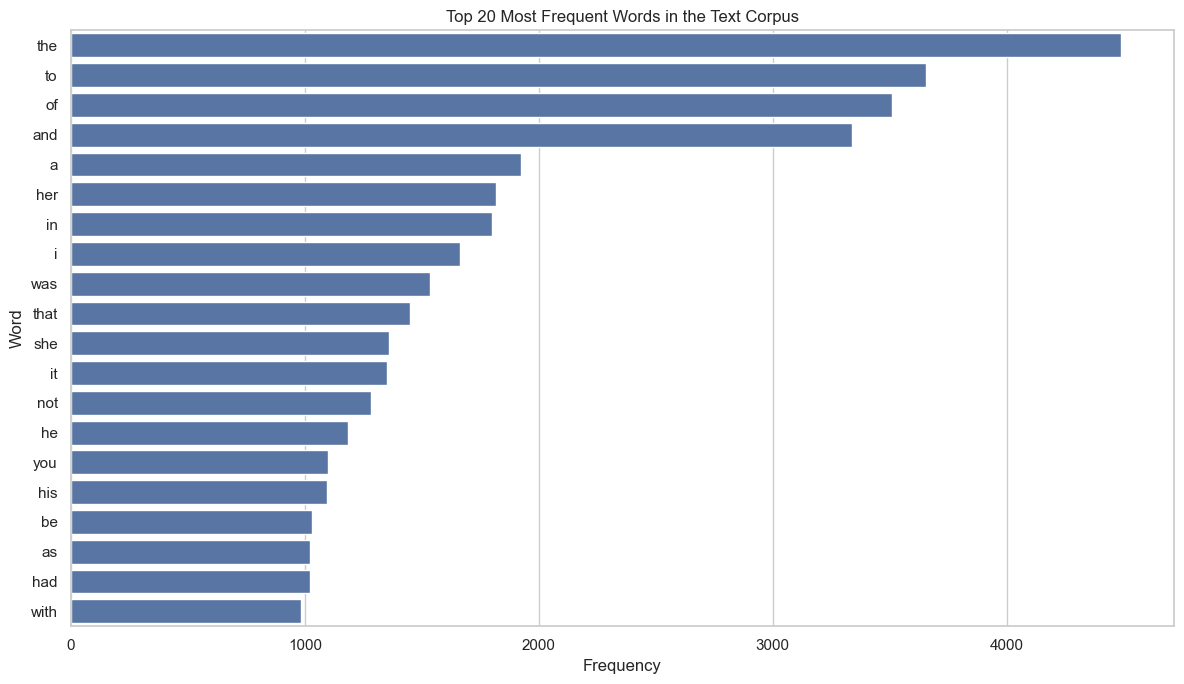

,Word,Frequency
0,the,4491
1,to,3656
2,of,3511
3,and,3339
4,a,1923
5,her,1817
6,in,1801
7,i,1663
8,was,1536
9,that,1449


In [19]:
top_words = word_freq.most_common(20)

frequency_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=frequency_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequent Words in the Text Corpus")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "top_20_words.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

display(frequency_df)

In [20]:
content_freq = Counter(content_tokens)

content_frequency_df = pd.DataFrame(
    content_freq.most_common(20),
    columns=["Content Word", "Frequency"]
)

display(content_frequency_df)

,Content Word,Frequency
0,mr,802
1,elizabeth,634
2,could,562
3,would,516
4,said,437
5,darcy,432
6,mrs,356
7,much,348
8,one,345
9,must,344


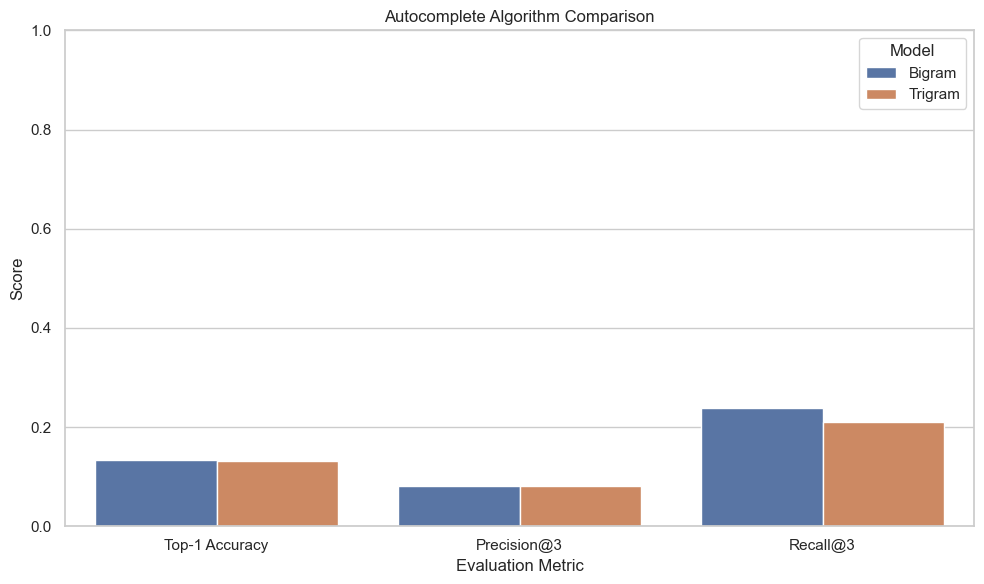

In [21]:
metrics_long = autocomplete_metrics.melt(
    id_vars=["Model", "Evaluated Contexts"],
    value_vars=[
        "Top-1 Accuracy",
        "Precision@3",
        "Recall@3"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=metrics_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Autocomplete Algorithm Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "autocomplete_model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

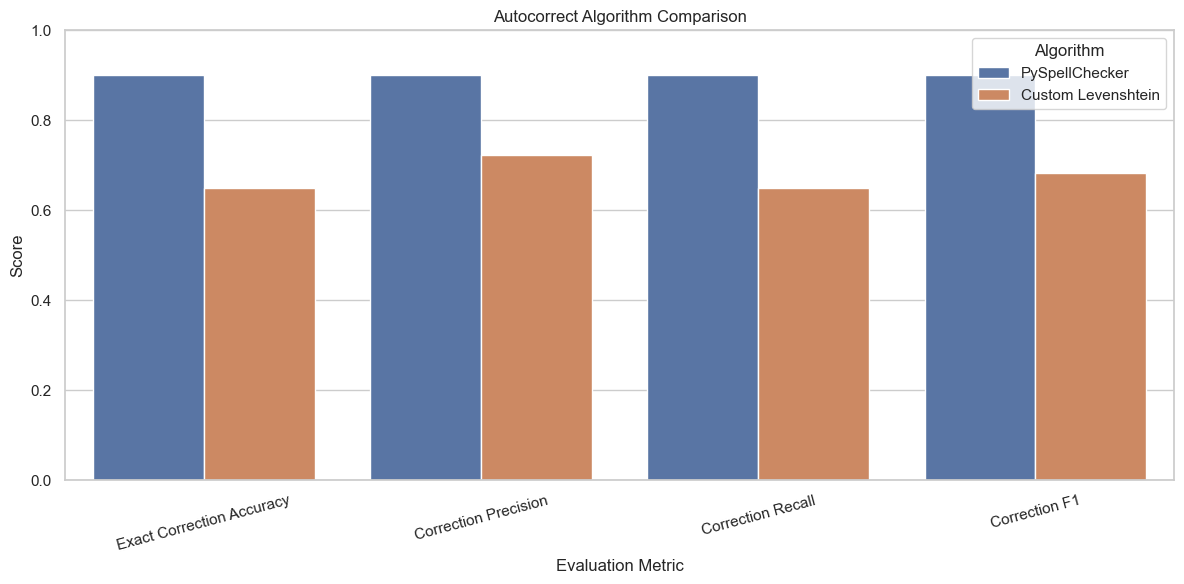

In [22]:
metrics_long = spell_metrics.melt(
    id_vars=["Algorithm", "Test Words"],
    value_vars=[
        "Exact Correction Accuracy",
        "Correction Precision",
        "Correction Recall",
        "Correction F1"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_long,
    x="Metric",
    y="Score",
    hue="Algorithm"
)

plt.ylim(0, 1)
plt.title("Autocorrect Algorithm Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "autocorrect_model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [23]:
prediction_df.to_csv(
    OUTPUT_DIR / "autocomplete_prefix_tests.csv",
    index=False
)

autocomplete_metrics.to_csv(
    OUTPUT_DIR / "autocomplete_metrics.csv",
    index=False
)

correction_df.to_csv(
    OUTPUT_DIR / "autocorrect_test_results.csv",
    index=False
)

spell_metrics.to_csv(
    OUTPUT_DIR / "autocorrect_metrics.csv",
    index=False
)

detection_df.to_csv(
    OUTPUT_DIR / "autocorrect_detection_results.csv",
    index=False
)

frequency_df.to_csv(
    OUTPUT_DIR / "top_20_words.csv",
    index=False
)

print("All result tables and visualizations have been saved.")

All result tables and visualizations have been saved.
